In [1]:
# ==========================================================
# BLOCK 1
# Coordinated HIF Simulator + Data Collection
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ----------------------------------------------------------
# PARAMETERS
# ----------------------------------------------------------

TIMESTEPS = 1_000_000
HORIZON = 1_00_000
SAMPLE_EVERY = 50

ROWS = 10
COLS = 10
N_NODES = ROWS * COLS

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

# ----------------------------------------------------------
# GRID GRAPH
# ----------------------------------------------------------

# ----------------------------------------------------------
# GRID GRAPH WITH 10% EDGE REMOVAL
# ----------------------------------------------------------

def build_grid_graph(
    rows=10,
    cols=10,
    remove_fraction=0.10
):

    rng = np.random.default_rng()

    N = rows * cols

    neighbors = [[] for _ in range(N)]
    edges = []

    for r in range(rows):
        for c in range(cols):

            node = r * cols + c

            if r < rows - 1:

                down = (r + 1) * cols + c

                neighbors[node].append(down)
                neighbors[down].append(node)

                edges.append((node, down))

            if c < cols - 1:

                right = r * cols + c + 1

                neighbors[node].append(right)
                neighbors[right].append(node)

                edges.append((node, right))

    def is_connected(adj):

        visited = np.zeros(N, dtype=bool)

        stack = [0]
        visited[0] = True

        while stack:

            u = stack.pop()

            for v in adj[u]:

                if not visited[v]:

                    visited[v] = True
                    stack.append(v)

        return visited.all()

    num_remove = int(
        remove_fraction * len(edges)
    )

    removed = 0

    candidate_edges = edges.copy()

    rng.shuffle(candidate_edges)

    for u, v in candidate_edges:

        if removed >= num_remove:
            break

        neighbors[u].remove(v)
        neighbors[v].remove(u)

        if is_connected(neighbors):

            removed += 1

        else:

            neighbors[u].append(v)
            neighbors[v].append(u)

    print(
        f"Removed {removed} edges "
        f"out of {len(edges)}"
    )

    return [
        np.array(
            nbrs,
            dtype=np.int32
        )
        for nbrs in neighbors
    ]

# ----------------------------------------------------------
# ROBOT
# ----------------------------------------------------------

class Robot:

    def __init__(self, start_node, neighbors, rng):

        self.position = start_node
        self.neighbors = neighbors
        self.rng = rng

    def choose_next(
        self,
        idleness,
        forbidden=None
    ):

        nbrs = self.neighbors[
            self.position
        ]

        if forbidden is not None:

            filtered = [
                n for n in nbrs
                if n != forbidden
            ]

            if len(filtered) > 0:
                nbrs = np.array(
                    filtered,
                    dtype=np.int32
                )

        vals = idleness[nbrs]

        mx = vals.max()

        candidates = nbrs[
            vals == mx
        ]

        return int(
            self.rng.choice(
                candidates
            )
        )

# ----------------------------------------------------------
# COORDINATED HIF SIMULATOR
# ----------------------------------------------------------

class CoordinatedHIFSimulator:

    def __init__(self):

        self.rng = np.random.default_rng(
            SEED
        )

        self.neighbors = build_grid_graph(
            ROWS,
            COLS,
            remove_fraction=0.10
        )

        self.idleness = np.zeros(
            N_NODES,
            dtype=np.int32
        )

        self.robot1 = Robot(
            0,
            self.neighbors,
            self.rng
        )

        self.robot2 = Robot(
            N_NODES - 1,
            self.neighbors,
            self.rng
        )

    def step(self):

        self.idleness += 1

        next1 = self.robot1.choose_next(
            self.idleness
        )

        next2 = self.robot2.choose_next(
            self.idleness,
            forbidden=next1
        )

        self.robot1.position = next1
        self.robot2.position = next2

        self.idleness[next1] = 0
        self.idleness[next2] = 0

        iai = self.idleness.mean()
        max_idle = self.idleness.max()

        return iai, max_idle

# ----------------------------------------------------------
# DATA COLLECTION
# ----------------------------------------------------------

def collect_simulation_data():

    sim = CoordinatedHIFSimulator()

    sampled_states = []

    iai_history = np.zeros(
        TIMESTEPS,
        dtype=np.float32
    )

    maxidle_history = np.zeros(
        TIMESTEPS,
        dtype=np.float32
    )

    print(
        f"\nRunning {TIMESTEPS:,} steps..."
    )

    for t in tqdm(range(TIMESTEPS)):

        iai, mx = sim.step()

        iai_history[t] = iai
        maxidle_history[t] = mx

        if (
            t % SAMPLE_EVERY == 0
            and
            t + HORIZON < TIMESTEPS
        ):

            # --------------------
            # 100 idleness values
            # --------------------

            idle_vec = (
                sim.idleness.astype(
                    np.float32
                )
            )

            # --------------------
            # Robot 1 one-hot
            # --------------------

            r1 = np.zeros(
                N_NODES,
                dtype=np.float32
            )

            r1[
                sim.robot1.position
            ] = 1.0

            # --------------------
            # Robot 2 one-hot
            # --------------------

            r2 = np.zeros(
                N_NODES,
                dtype=np.float32
            )

            r2[
                sim.robot2.position
            ] = 1.0

            state = np.concatenate(
                [
                    idle_vec,
                    r1,
                    r2
                ]
            )

            sampled_states.append(
                (
                    t,
                    state
                )
            )

    print(
        "\nSimulation complete."
    )

    return (
        sampled_states,
        iai_history,
        maxidle_history
    )

# ----------------------------------------------------------
# RUN DATA COLLECTION
# ----------------------------------------------------------

sampled_states, iai_history, maxidle_history = (
    collect_simulation_data()
)

print(
    "\nNumber of sampled states:",
    len(sampled_states)
)

print(
    "State dimension:",
    sampled_states[0][1].shape
)

Removed 18 edges out of 180

Running 1,000,000 steps...


100%|██████████| 1000000/1000000 [01:13<00:00, 13587.89it/s]


Simulation complete.

Number of sampled states: 18000
State dimension: (300,)


In [2]:
# ==========================================================
# BLOCK 2
# Create Future-Horizon Labels
# ==========================================================

from collections import deque


# ----------------------------------------------------------
# Sliding Window Maximum
# O(N)
# ----------------------------------------------------------

def sliding_window_max(arr, window):

    n = len(arr)

    result = np.empty(
        n - window + 1,
        dtype=np.float32
    )

    dq = deque()

    for i in range(n):

        while dq and dq[0] <= i - window:
            dq.popleft()

        while dq and arr[dq[-1]] <= arr[i]:
            dq.pop()

        dq.append(i)

        if i >= window - 1:
            result[
                i - window + 1
            ] = arr[dq[0]]

    return result


# ----------------------------------------------------------
# Future Maxima
# ----------------------------------------------------------

print(
    "\nComputing future maxima..."
)

future_max_iai = sliding_window_max(
    iai_history,
    HORIZON
)

future_max_maxidle = sliding_window_max(
    maxidle_history,
    HORIZON
)

print(
    "Future maxima computed."
)

print(
    "Length:",
    len(future_max_iai)
)


# ----------------------------------------------------------
# Build Dataset
# ----------------------------------------------------------

X = []
Y = []

for t, state in sampled_states:

    if t >= len(future_max_iai):
        continue

    target = np.array(
        [
            future_max_iai[t],
            future_max_maxidle[t]
        ],
        dtype=np.float32
    )

    X.append(state)
    Y.append(target)

X = np.array(
    X,
    dtype=np.float32
)

Y = np.array(
    Y,
    dtype=np.float32
)

print("\nDataset Created")

print(
    "X shape:",
    X.shape
)

print(
    "Y shape:",
    Y.shape
)


# ----------------------------------------------------------
# Train / Val / Test Split
# ----------------------------------------------------------


X_train, X_temp, y_train, y_temp = (
    train_test_split(
        X,
        Y,
        test_size=0.30,
        random_state=SEED
    )
)

X_val, X_test, y_val, y_test = (
    train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=SEED
    )
)

print("\nSplit Sizes")

print(
    "Train:",
    len(X_train)
)

print(
    "Validation:",
    len(X_val)
)

print(
    "Test:",
    len(X_test)
)


# ----------------------------------------------------------
# PyTorch Dataset
# ----------------------------------------------------------

class PatrollingDataset(Dataset):

    def __init__(self, X, Y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.Y = torch.tensor(
            Y,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.X)

    def __getitem__(self, idx):

        return (
            self.X[idx],
            self.Y[idx]
        )


train_dataset = PatrollingDataset(
    X_train,
    y_train
)

val_dataset = PatrollingDataset(
    X_val,
    y_val
)

test_dataset = PatrollingDataset(
    X_test,
    y_test
)


train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print(
    "\nDataset preparation complete."
)


Computing future maxima...
Future maxima computed.
Length: 900001

Dataset Created
X shape: (18000, 300)
Y shape: (18000, 2)

Split Sizes
Train: 12600
Validation: 2700
Test: 2700

Dataset preparation complete.


Using device: cpu
PatrollingMLP(
  (net): Sequential(
    (0): Linear(in_features=300, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Epoch 001/100 | LR 0.000500 | Train 30.175734 | Val 12.311080
Epoch 002/100 | LR 0.000500 | Train 11.941425 | Val 11.883062
Epoch 003/100 | LR 0.000500 | Train 11.483855 | Val 11.006903
Epoch 004/100 | LR 0.000500 | Train 10.857041 | Val 10.715750
Epoch 005/100 | LR 0.000500 | Train 10.520031 | Val 10.579875
Epoch 006/100 | LR 0.000500 | Train 10.369214 | Val 10.801717
Epoch 007/100 | LR 0.000500 | Train 10.142763 | Val 10.945384
Epoch 008/100 | LR 0.000500 | Train 10.014388 | Val 10.179005
Epoch 009/100 | LR 0.000500 | Train 9.988060 | Val 10.470600
Epoch 010/100 | LR 0.000500 | Train 9.705984 | Val 10.250313
Epoch 011/100 | LR 0.000500 

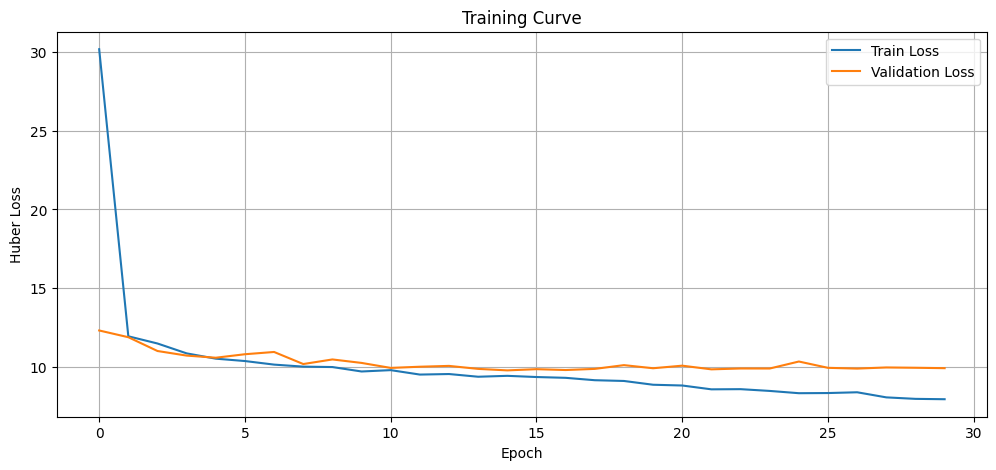

In [3]:
# ==========================================================
# BLOCK 3
# Huber Loss + Lower Learning Rate
# ==========================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", DEVICE)

# ----------------------------------------------------------
# MODEL
# ----------------------------------------------------------

class PatrollingMLP(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(300, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 2)

        )

    def forward(self, x):
        return self.net(x)

model = PatrollingMLP().to(DEVICE)

print(model)

# ----------------------------------------------------------
# LOSS
# ----------------------------------------------------------

criterion = nn.HuberLoss(delta=1.0)

# ----------------------------------------------------------
# OPTIMIZER
# ----------------------------------------------------------

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-4
)

# ----------------------------------------------------------
# LR SCHEDULER
# ----------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

# ----------------------------------------------------------
# TRAINING SETTINGS
# ----------------------------------------------------------

EPOCHS = 100

EARLY_STOPPING_PATIENCE = 15

best_val_loss = float("inf")

early_stop_counter = 0

train_losses = []
val_losses = []

# ----------------------------------------------------------
# TRAIN LOOP
# ----------------------------------------------------------

for epoch in range(EPOCHS):

    model.train()

    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad()

        preds = model(X_batch)

        loss = criterion(
            preds,
            y_batch
        )

        loss.backward()

        optimizer.step()

        running_train_loss += (
            loss.item()
            * X_batch.size(0)
        )

    train_loss = (
        running_train_loss
        /
        len(train_loader.dataset)
    )

    # ------------------------------------------------------
    # VALIDATION
    # ------------------------------------------------------

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            preds = model(X_batch)

            loss = criterion(
                preds,
                y_batch
            )

            running_val_loss += (
                loss.item()
                * X_batch.size(0)
            )

    val_loss = (
        running_val_loss
        /
        len(val_loader.dataset)
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:03d}/{EPOCHS} | "
        f"LR {current_lr:.6f} | "
        f"Train {train_loss:.6f} | "
        f"Val {val_loss:.6f}"
    )

    # ------------------------------------------------------
    # SAVE BEST MODEL
    # ------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_model.pt"
        )

        early_stop_counter = 0

    else:

        early_stop_counter += 1

    # ------------------------------------------------------
    # EARLY STOPPING
    # ------------------------------------------------------

    if early_stop_counter >= EARLY_STOPPING_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break

print("\nTraining Complete")

print(
    "Best Validation Loss:",
    best_val_loss
)

# ----------------------------------------------------------
# TRAINING CURVE
# ----------------------------------------------------------

plt.figure(figsize=(12,5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.title(
    "Training Curve"
)

plt.legend()
plt.grid(True)

plt.show()


FUTURE MAX IAI
MAE  : 2.9360
RMSE : 3.7457
R²   : -2.4707

FUTURE MAX MAXIDLE
MAE  : 17.7597
RMSE : 22.0566
R²   : -0.8017


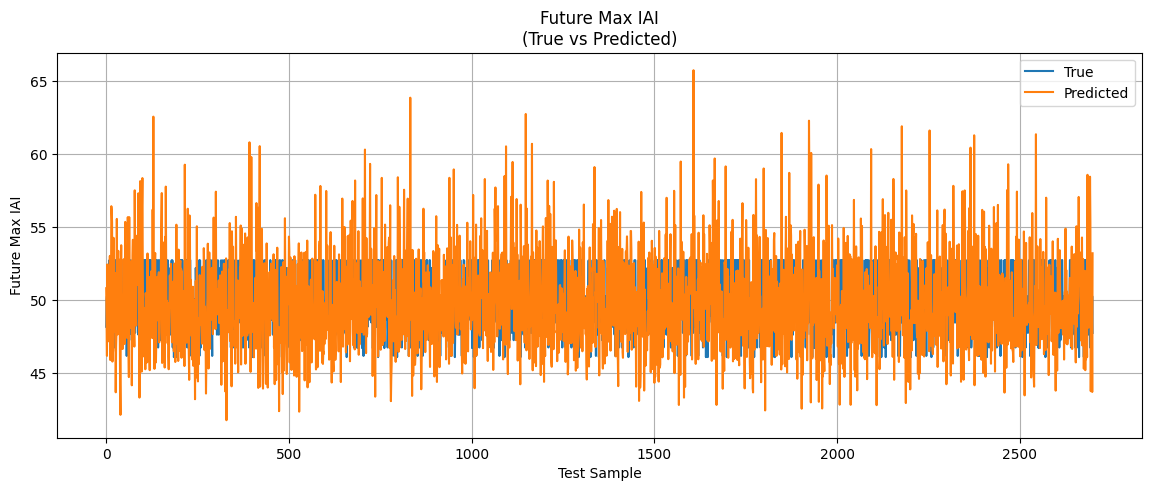

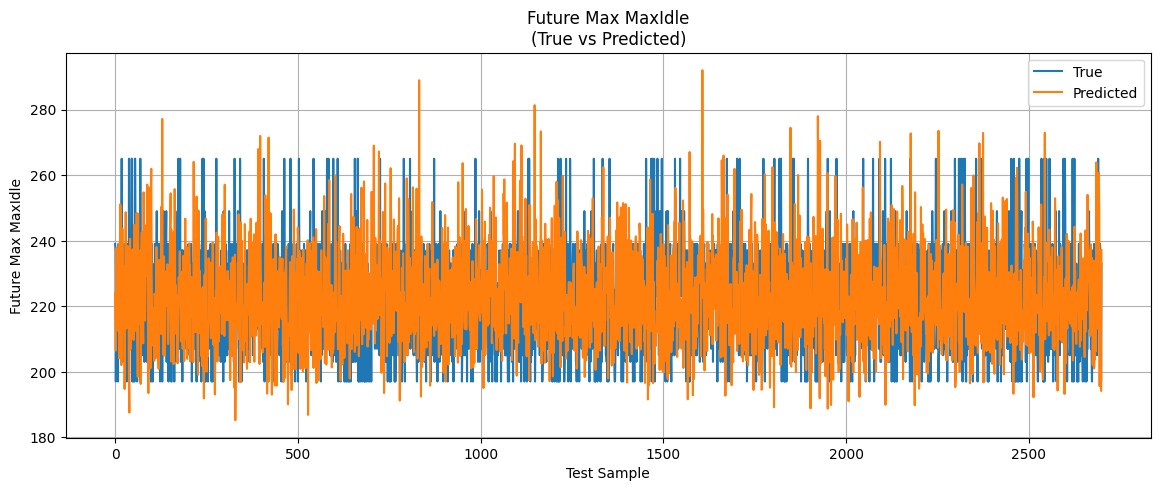

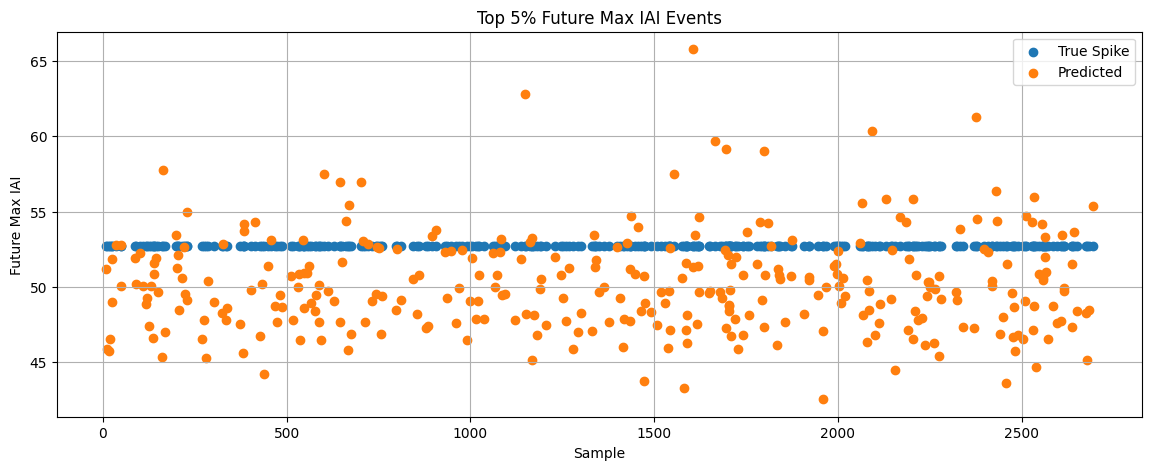

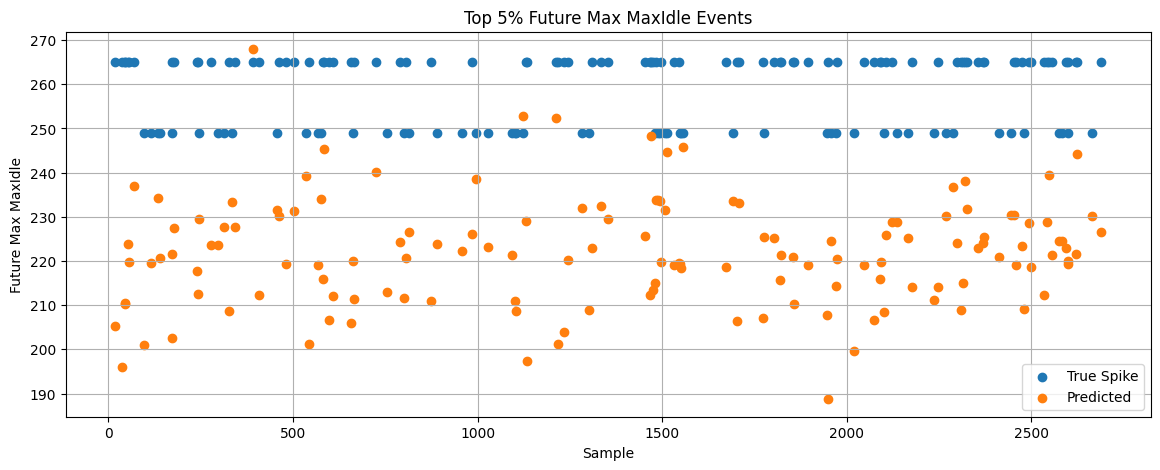

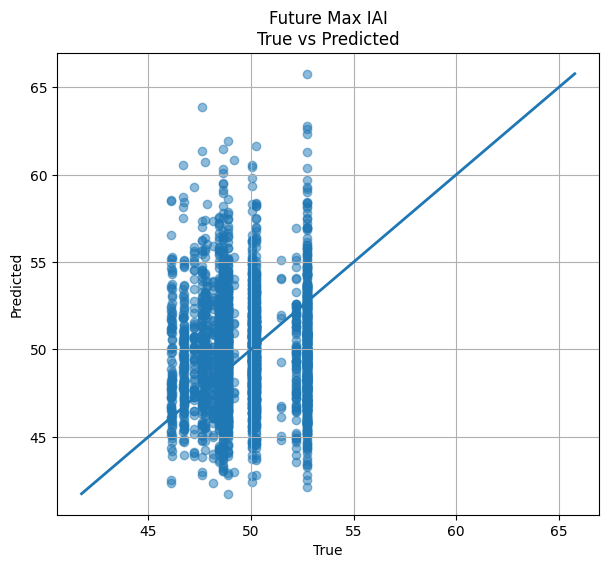

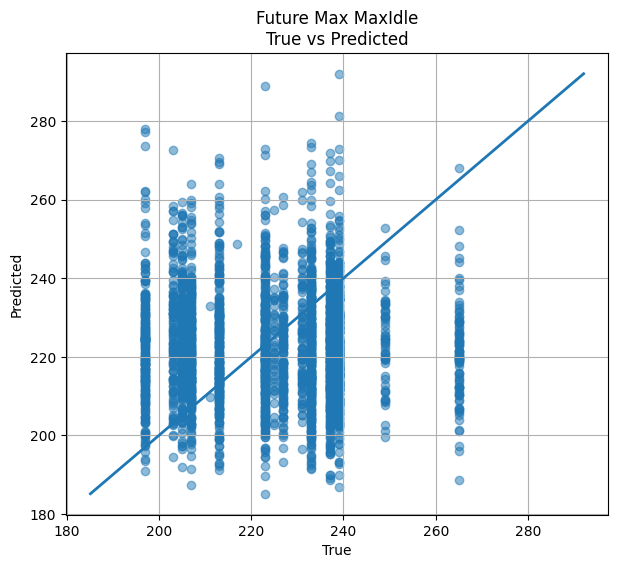


WORST IAI ERRORS
Sample 2468 | True=47.24 | Pred=59.32 | Error=12.08
Sample 1090 | True=46.08 | Pred=58.51 | Error=12.43
Sample 1971 | True=46.08 | Pred=58.54 | Error=12.46
Sample 1848 | True=48.64 | Pred=61.47 | Error=12.83
Sample 1165 | True=47.74 | Pred=60.72 | Error=12.98
Sample 2177 | True=48.90 | Pred=61.93 | Error=13.03
Sample 1607 | True=52.74 | Pred=65.77 | Error=13.03
Sample 2544 | True=47.62 | Pred=61.38 | Error=13.76
Sample 420 | True=46.70 | Pred=60.56 | Error=13.86
Sample 832 | True=47.62 | Pred=63.89 | Error=16.27

10 WORST MAXIDLE ERRORS
Sample 99 | True=197.00 | Pred=261.93 | Error=64.93
Sample 754 | True=197.00 | Pred=262.11 | Error=65.11
Sample 832 | True=223.00 | Pred=288.97 | Error=65.97
Sample 1133 | True=265.00 | Pred=197.32 | Error=67.68
Sample 38 | True=265.00 | Pred=195.95 | Error=69.05
Sample 2177 | True=203.00 | Pred=272.72 | Error=69.72
Sample 1950 | True=265.00 | Pred=188.71 | Error=76.29
Sample 2253 | True=197.00 | Pred=273.53 | Error=76.53
Sample 129 | 

In [4]:
# ==========================================================
# BLOCK 4
# EVALUATION
# ==========================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

model.load_state_dict(
    torch.load(
        "best_model.pt",
        map_location=DEVICE
    )
)

model.eval()

predictions = []

with torch.no_grad():

    for X_batch, _ in test_loader:

        X_batch = X_batch.to(DEVICE)

        preds = model(X_batch)

        predictions.append(
            preds.cpu().numpy()
        )

predictions = np.vstack(predictions)

y_true = y_test

# ----------------------------------------------------------
# METRICS
# ----------------------------------------------------------

iai_mae = mean_absolute_error(
    y_true[:,0],
    predictions[:,0]
)

iai_rmse = np.sqrt(
    mean_squared_error(
        y_true[:,0],
        predictions[:,0]
    )
)

iai_r2 = r2_score(
    y_true[:,0],
    predictions[:,0]
)

mx_mae = mean_absolute_error(
    y_true[:,1],
    predictions[:,1]
)

mx_rmse = np.sqrt(
    mean_squared_error(
        y_true[:,1],
        predictions[:,1]
    )
)

mx_r2 = r2_score(
    y_true[:,1],
    predictions[:,1]
)

print("\n==========================")
print("FUTURE MAX IAI")
print("==========================")

print(f"MAE  : {iai_mae:.4f}")
print(f"RMSE : {iai_rmse:.4f}")
print(f"R²   : {iai_r2:.4f}")

print("\n==========================")
print("FUTURE MAX MAXIDLE")
print("==========================")

print(f"MAE  : {mx_mae:.4f}")
print(f"RMSE : {mx_rmse:.4f}")
print(f"R²   : {mx_r2:.4f}")

# ----------------------------------------------------------
# TRUE vs PREDICTED TIME SERIES
# ----------------------------------------------------------

plt.figure(figsize=(14,5))

plt.plot(
    y_true[:,0],
    label="True",
    linewidth=1.5
)

plt.plot(
    predictions[:,0],
    label="Predicted",
    linewidth=1.5
)

plt.title(
    "Future Max IAI\n(True vs Predicted)"
)

plt.xlabel("Test Sample")
plt.ylabel("Future Max IAI")

plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(14,5))

plt.plot(
    y_true[:,1],
    label="True",
    linewidth=1.5
)

plt.plot(
    predictions[:,1],
    label="Predicted",
    linewidth=1.5
)

plt.title(
    "Future Max MaxIdle\n(True vs Predicted)"
)

plt.xlabel("Test Sample")
plt.ylabel("Future Max MaxIdle")

plt.legend()
plt.grid(True)

plt.show()

# ----------------------------------------------------------
# SPIKES ONLY
# ----------------------------------------------------------

iai_threshold = np.percentile(
    y_true[:,0],
    95
)

mx_threshold = np.percentile(
    y_true[:,1],
    95
)

plt.figure(figsize=(14,5))

spikes = y_true[:,0] >= iai_threshold

plt.scatter(
    np.where(spikes)[0],
    y_true[spikes,0],
    label="True Spike"
)

plt.scatter(
    np.where(spikes)[0],
    predictions[spikes,0],
    label="Predicted"
)

plt.title("Top 5% Future Max IAI Events")

plt.xlabel("Sample")
plt.ylabel("Future Max IAI")

plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(14,5))

spikes = y_true[:,1] >= mx_threshold

plt.scatter(
    np.where(spikes)[0],
    y_true[spikes,1],
    label="True Spike"
)

plt.scatter(
    np.where(spikes)[0],
    predictions[spikes,1],
    label="Predicted"
)

plt.title("Top 5% Future Max MaxIdle Events")

plt.xlabel("Sample")
plt.ylabel("Future Max MaxIdle")

plt.legend()
plt.grid(True)

plt.show()

# ----------------------------------------------------------
# SCATTER PLOTS
# ----------------------------------------------------------

plt.figure(figsize=(7,6))

plt.scatter(
    y_true[:,0],
    predictions[:,0],
    alpha=0.5
)

mn = min(
    y_true[:,0].min(),
    predictions[:,0].min()
)

mx = max(
    y_true[:,0].max(),
    predictions[:,0].max()
)

plt.plot(
    [mn,mx],
    [mn,mx],
    linewidth=2
)

plt.xlabel("True")
plt.ylabel("Predicted")

plt.title(
    "Future Max IAI\nTrue vs Predicted"
)

plt.grid(True)

plt.show()

plt.figure(figsize=(7,6))

plt.scatter(
    y_true[:,1],
    predictions[:,1],
    alpha=0.5
)

mn = min(
    y_true[:,1].min(),
    predictions[:,1].min()
)

mx = max(
    y_true[:,1].max(),
    predictions[:,1].max()
)

plt.plot(
    [mn,mx],
    [mn,mx],
    linewidth=2
)

plt.xlabel("True")
plt.ylabel("Predicted")

plt.title(
    "Future Max MaxIdle\nTrue vs Predicted"
)

plt.grid(True)

plt.show()

# ----------------------------------------------------------
# WORST PREDICTIONS
# ----------------------------------------------------------
print("\n==========================")
print("WORST IAI ERRORS")
print("==========================")

worst_idx = np.argsort(
    np.abs(y_true[:,0] - predictions[:,0])
)[-10:]

for idx in worst_idx:

    print(
        f"Sample {idx} | "
        f"True={y_true[idx,0]:.2f} | "
        f"Pred={predictions[idx,0]:.2f} | "
        f"Error={abs(y_true[idx,0]-predictions[idx,0]):.2f}"
    )

error = np.abs(
    predictions[:,1] - y_true[:,1]
)

worst = np.argsort(error)[-10:]

print("\n==========================")
print("10 WORST MAXIDLE ERRORS")
print("==========================")

for idx in worst:

    print(
        f"Sample {idx} | "
        f"True={y_true[idx,1]:.2f} | "
        f"Pred={predictions[idx,1]:.2f} | "
        f"Error={error[idx]:.2f}"
    )
